# Final Visualizations — Enterprise Multi-Modal Data Visualization

**Course:** Database Knowledge Extraction
**Project:** Enterprise Multi-Modal Data Visualization and Storytelling
**Owner:** Laura (Role 3 — Python Visualization Specialist)
**Status:** Scaffold — run every cell after Role 1 delivers `data/processed/clean_dataset.csv`.

## Objectives

This notebook covers the programmatic visual taxonomy required by the rubric:

1. **Distributions & spread** — histogram + KDE and box/violin plots.
2. **Uncertainty & variability** — monthly trend with a 95% confidence interval band.
3. **X–Y relationships** — Seaborn correlation heatmap with a diverging palette centered at 0.
4. **Interactive web component** — Plotly scatter/bubble plot with hover, zoom, and color.
5. **Export** — high-resolution PNGs and a standalone interactive HTML file.

> **QA rule (Role 5):** the final version must run top-to-bottom with
> `Kernel → Restart & Run All` and produce every asset listed in section 5.

## 0. Environment setup

Run from the repository root or from the `notebooks/` folder. Paths are resolved relative to
the project root, so no absolute paths are required.

```bash
pip install -r requirements.txt
jupyter notebook notebooks/final_visualizations.ipynb
```

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Resolve the project root whether the notebook is launched from the root or notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "clean_dataset.csv"
PLOTS_DIR = PROJECT_ROOT / "assets" / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Declutter every Matplotlib/Seaborn chart by default.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

print(f"Project root: {PROJECT_ROOT}")
print(f"Data file:    {DATA_PATH}")
print(f"Plots folder: {PLOTS_DIR}")

Project root: c:\Users\52984\Documents\GitHub\db-knowledge-extraction-final
Data file:    c:\Users\52984\Documents\GitHub\db-knowledge-extraction-final\data\processed\clean_dataset.csv
Plots folder: c:\Users\52984\Documents\GitHub\db-knowledge-extraction-final\assets\plots


In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["Order Date", "Ship Date"])

print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
print(f"Date range: {df['Order Date'].min():%Y-%m-%d} -> {df['Order Date'].max():%Y-%m-%d}")
df.head()

Rows: 9,994 | Columns: 27
Date range: 2014-01-03 -> 2017-12-30


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Quarter,Shipping Days,Profit Margin,Is Loss
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.9600,2,0.00,41.9136,2016,2016-11,2016Q4,3,0.1600,False
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.9400,3,0.00,219.5820,2016,2016-11,2016Q4,3,0.3000,False
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.6200,2,0.00,6.8714,2016,2016-06,2016Q2,4,0.4700,False
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,957.5775,5,0.45,-383.0310,2015,2015-10,2015Q4,7,-0.4000,True
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,22.3680,2,0.20,2.5164,2015,2015-10,2015Q4,7,0.1125,False


In [3]:
# Quick data-quality sanity check before plotting.
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
quality.sort_values("missing", ascending=False)

,dtype,missing,missing_pct,unique
Row ID,int64,0,0.0,9994
Order ID,str,0,0.0,5009
Order Date,datetime64[us],0,0.0,1237
Ship Date,datetime64[us],0,0.0,1334
Ship Mode,str,0,0.0,4
Customer ID,str,0,0.0,793
Customer Name,str,0,0.0,793
Segment,str,0,0.0,3
Country,str,0,0.0,1
City,str,0,0.0,531


## 1. Distributions & spread

**Question:** How are revenue and profit distributed, and where are the outliers?

- `Sales` is typically right-skewed: a few high-value orders dominate revenue.
- `Profit` contains both positive and negative values; the box plot exposes loss-making
  categories and extreme outliers.

**Design choices:** 50 bins for the histogram, KDE overlay for shape, box plot for spread and
outliers. Top/right spines removed, no redundant legend.

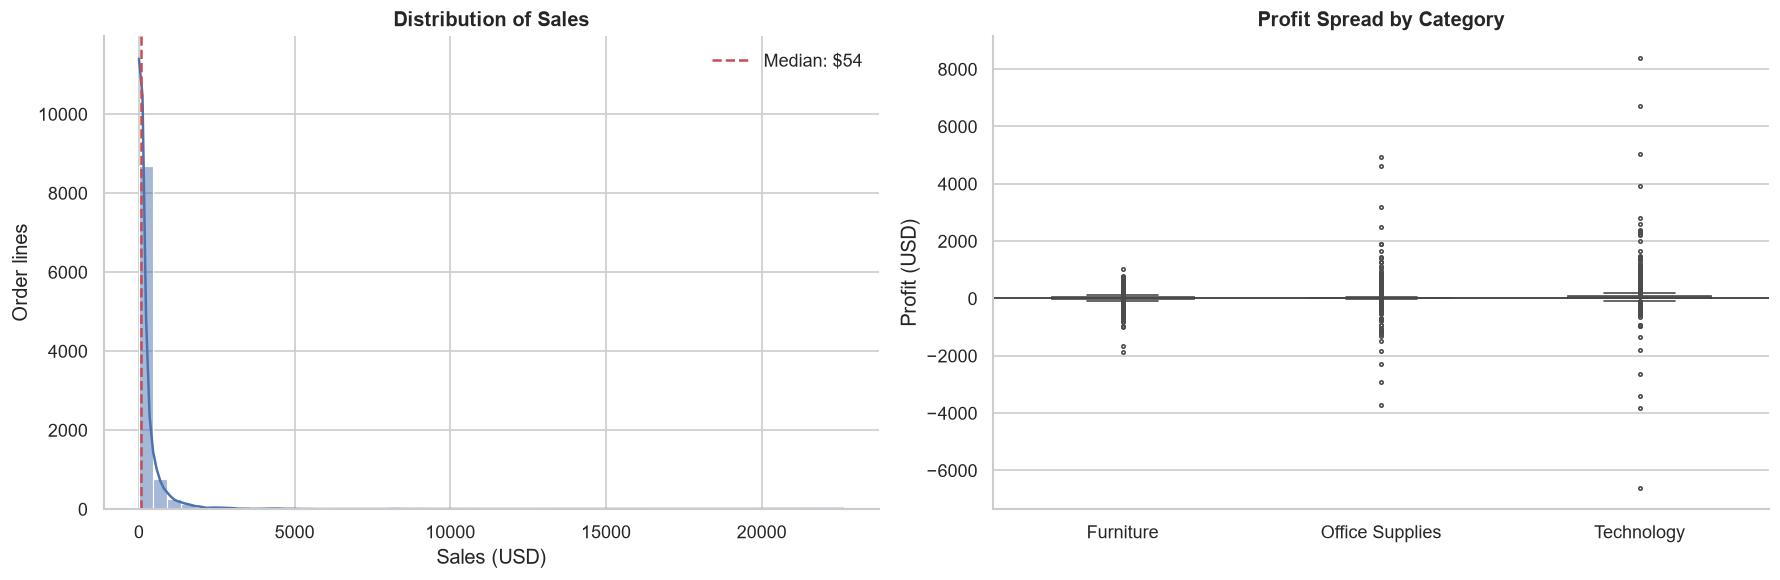

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df,
    x="Sales",
    bins=50,
    kde=True,
    color="#4C72B0",
    edgecolor="white",
    ax=axes[0],
)
axes[0].set_title("Distribution of Sales")
axes[0].set_xlabel("Sales (USD)")
axes[0].set_ylabel("Order lines")
axes[0].axvline(df["Sales"].median(), color="#C44E52", linestyle="--", linewidth=1.5,
                label=f"Median: ${df['Sales'].median():,.0f}")
axes[0].legend(frameon=False)

sns.boxplot(
    data=df,
    x="Category",
    y="Profit",
    color="#4C72B0",
    width=0.55,
    fliersize=2,
    ax=axes[1],
)
axes[1].axhline(0, color="#333333", linewidth=1)
axes[1].set_title("Profit Spread by Category")
axes[1].set_xlabel("")
axes[1].set_ylabel("Profit (USD)")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "distribution_kde.png", bbox_inches="tight")
plt.show()

**Interpretation (complete after running):**

- Skewness of `Sales`: TBD
- Median profit: TBD
- Category with the widest spread: TBD
- Share of loss-making order lines: TBD

## 2. Uncertainty & variability

**Question:** How confident are we in the monthly profit trend?

The shaded band is a **95% confidence interval** for the mean monthly profit
(`errorbar=("ci", 95)`). A wider band means more uncertainty; overlapping bands across months
mean the difference may not be meaningful.

**Design choices:** zero reference line, marker per month, no top/right spines.

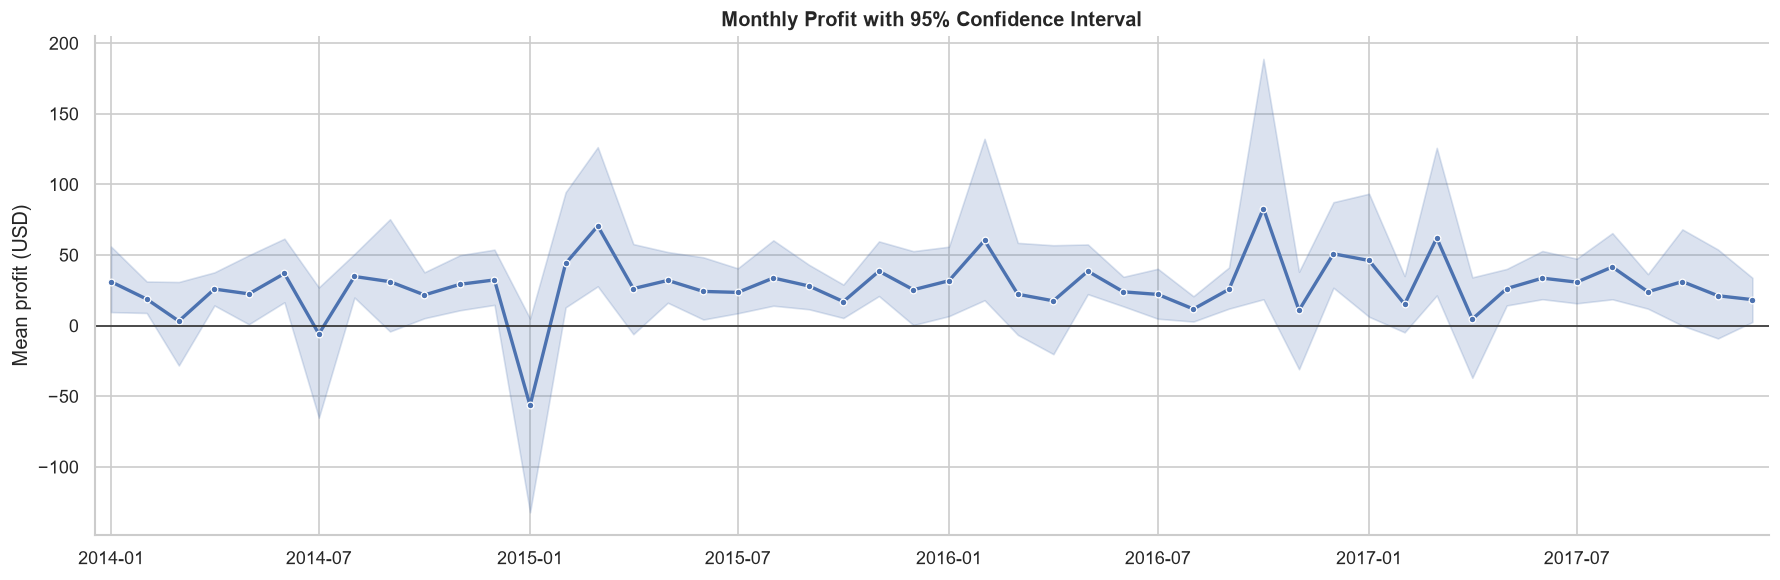

In [5]:
# Convert the period string to a timestamp so the x-axis is ordered correctly.
df["Order Month Date"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()

fig, ax = plt.subplots(figsize=(15, 5))
sns.lineplot(
    data=df,
    x="Order Month Date",
    y="Profit",
    errorbar=("ci", 95),
    n_boot=1000,
    marker="o",
    markersize=4,
    linewidth=2,
    color="#4C72B0",
    ax=ax,
)
ax.axhline(0, color="#333333", linewidth=1)
ax.set_title("Monthly Profit with 95% Confidence Interval")
ax.set_xlabel("")
ax.set_ylabel("Mean profit (USD)")
ax.margins(x=0.01)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "uncertainty_ci.png", bbox_inches="tight")
plt.show()

**Interpretation (complete after running):**

- Months with a confidence band entirely below zero: TBD
- Widest uncertainty: TBD
- Overall direction of the trend: TBD

## 3. X–Y relationships & correlation heatmap

**Question:** Which numeric variables move together, and which move in opposite directions?

The heatmap uses a **diverging palette centered at 0** (`vlag`): blue for positive
correlation, red for negative. The upper triangle is masked to avoid duplicate information.

> Correlation is **association, not causation**. Discount and profit may be related because
> both depend on category and pricing policy.

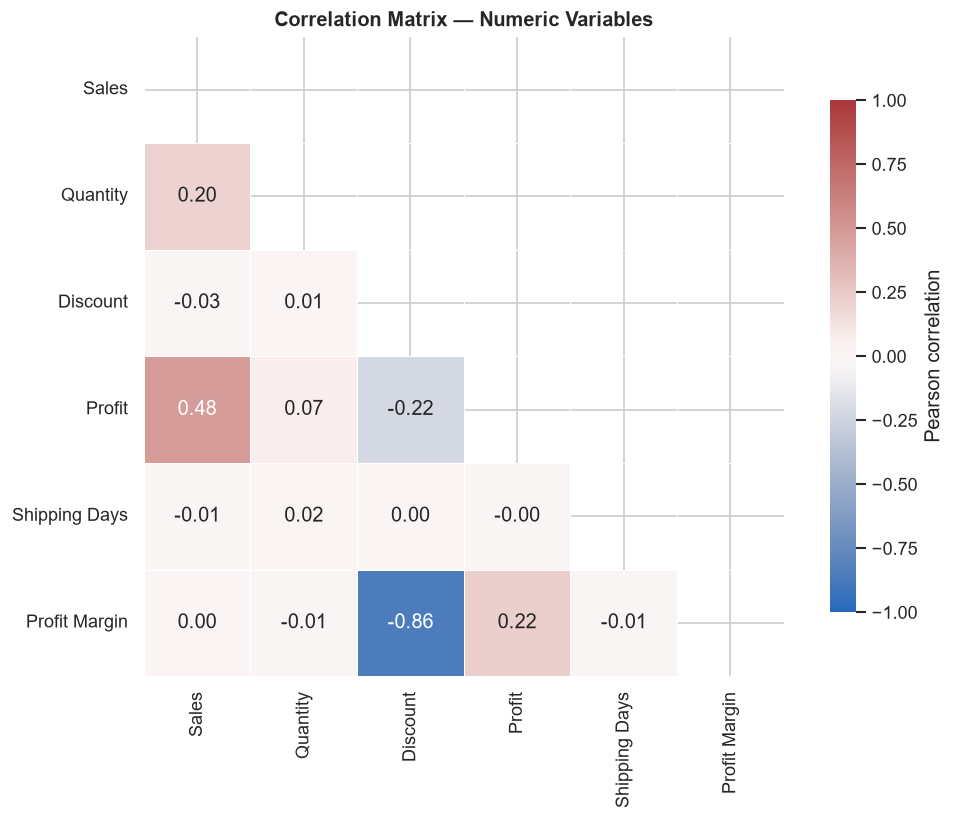

In [6]:
numeric_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Shipping Days",
    "Profit Margin",
]
available_numeric = [column for column in numeric_columns if column in df.columns]
corr = df[available_numeric].corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.6,
    cbar_kws={"shrink": 0.8, "label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Correlation Matrix — Numeric Variables")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "correlation_heatmap.png", bbox_inches="tight")
plt.show()

**Interpretation (complete after running):**

- Strongest positive relationship: TBD
- Strongest negative relationship: TBD
- Is `Discount` negatively associated with `Profit`? TBD

## 4. Interactive web component

**Question:** Which discount levels are associated with losses, and does the pattern differ by
category?

This Plotly bubble chart supports hover tooltips, zoom, pan, and legend filtering. Bubble size
encodes `Sales`; color encodes `Category` with a colorblind-safe qualitative palette.

The output is a standalone HTML file (`include_plotlyjs="cdn"`) that can be embedded in the
presentation or opened directly in a browser.

In [7]:
fig = px.scatter(
    df,
    x="Discount",
    y="Profit",
    color="Category",
    size="Sales",
    size_max=28,
    opacity=0.6,
    hover_data={
        "Order ID": True,
        "Product Name": True,
        "Sub-Category": True,
        "Region": True,
        "Sales": ":.2f",
        "Profit": ":.2f",
    },
    color_discrete_sequence=px.colors.qualitative.Safe,
    title="Discount vs. Profit by Category (bubble size = Sales)",
    labels={"Discount": "Discount rate", "Profit": "Profit (USD)"},
)
fig.add_hline(y=0, line_dash="dash", line_color="#555555")
fig.update_layout(
    template="plotly_white",
    legend_title_text="Category",
    hovermode="closest",
    margin=dict(l=40, r=20, t=60, b=40),
)
fig.write_html(PLOTS_DIR / "interactive_scatter.html", include_plotlyjs="cdn")
fig.show()

## 5. Export verification

Every asset below is required by the project brief. The final notebook must show **OK** for all
five files.

In [8]:
expected_assets = [
    "distribution_kde.png",
    "correlation_heatmap.png",
    "uncertainty_ci.png",
    "interactive_scatter.html",
]

for name in expected_assets:
    path = PLOTS_DIR / name
    status = "OK" if path.exists() else "MISSING"
    size_kb = path.stat().st_size / 1024 if path.exists() else 0
    print(f"{status:<8} {name:<30} {size_kb:,.1f} KB")

OK       distribution_kde.png           156.5 KB
OK       correlation_heatmap.png        157.0 KB
OK       uncertainty_ci.png             360.7 KB
OK       interactive_scatter.html       1,171.9 KB


In [9]:
import pandas as pd

subcategory = df.groupby("Sub-Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

subcategory["Margin (%)"] = (
    subcategory["Profit"] / subcategory["Sales"] * 100
)

print("LOWEST PROFITABILITY SUB-CATEGORIES")
display(subcategory.sort_values("Profit").head(5).round(2))

discount_data = df.copy()

discount_data["Discount Band"] = pd.cut(
    discount_data["Discount"],
    bins=[-0.001, 0.10, 0.20, 0.30, 0.40, 1.0],
    labels=["0-10%", "10-20%", "20-30%", "30-40%", ">40%"]
)

discount_data["Is Loss"] = discount_data["Profit"] < 0

discount_risk = discount_data.groupby(
    "Discount Band", observed=True
).agg(
    Transactions=("Profit", "size"),
    Loss_Rate=("Is Loss", "mean"),
    Total_Profit=("Profit", "sum")
)

discount_risk["Loss_Rate"] *= 100

print("\nDISCOUNT RISK ANALYSIS")
display(discount_risk.round(2))

opportunity = df.groupby(["Segment", "Region"]).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

opportunity["Margin (%)"] = (
    opportunity["Profit"] / opportunity["Sales"] * 100
)

print("\nBEST SEGMENT AND REGION")
display(
    opportunity.sort_values(
        "Margin (%)", ascending=False
    ).head(5).round(2)
)

LOWEST PROFITABILITY SUB-CATEGORIES


,Sales,Profit,Margin (%)
Sub-Category,,,
Tables,206965.53,-17725.48,-8.56
Bookcases,114880.00,-3472.56,-3.02
Supplies,46673.54,-1189.10,-2.55
Fasteners,3024.28,949.52,31.40
Machines,189238.63,3384.76,1.79



DISCOUNT RISK ANALYSIS


,Transactions,Loss_Rate,Total_Profit
Discount Band,,,
0-10%,4892,0.08,330016.78
10-20%,3709,13.99,91756.30
20-30%,227,91.63,-10369.28
30-40%,233,88.84,-25448.19
>40%,933,100.00,-99558.59



BEST SEGMENT AND REGION


,,Sales,Profit,Margin (%)
Segment,Region,,,
Home Office,East,127463.73,26709.22,20.95
Consumer,West,362880.77,57450.60,15.83
Corporate,West,225855.27,34437.43,15.25
Consumer,South,195580.97,26913.57,13.76
Home Office,Central,91212.64,12438.41,13.64


## 6. Findings for the executive story

Complete these bullets and send them to Josmar (Role 4) for the deck. Keep each insight one sentence and tie it to a recommendation.

1. **Revenue:** Sales are positively skewed, with an average of $229.86 and a median of $54.49 — monitor high-value transactions and revenue concentration.

2. **Profitability:** Tables (-$17,725.48), Bookcases (-$3,472.56), and Supplies (-$1,189.10) generate negative total profits — prioritize these sub-categories for pricing and cost optimization.

3. **Risk:** Discounts above 20% and up to 30% are associated with a 91.63% transaction loss rate — review discounts exceeding 20% and implement profitability-based approval controls.

4. **Opportunity:** The Home Office segment in the East region achieves the highest observed profit margin (20.95%) — investigate opportunities to replicate its profitable sales mix.

5. **Recommendation:** Prioritize a profitability-based discount policy, focusing on transactions discounted above 20% and loss-making sub-categories to protect overall margins.

### Handoff checklist

- [ ] Notebook executed from top to bottom (`Kernel → Restart & Run All`).
- [x] Markdown interpretation filled in for sections 1–3.
- [x] All four required visualization types exported to `assets/plots/`.
- [ ] Findings sent to Role 4 (Josmar) and Role 5 (Jesus).
- [ ] No absolute local paths in the notebook.

# 1. Dataset Exploration and Validation

This section explores and validates the Superstore dataset before
performing statistical analysis and data visualization.

The objective is to verify data quality, identify the available
variables, and ensure the dataset meets the project requirements.

## Dataset Overview

The dataset contains:

1. **Total Records:** 9,994 rows.
2. **Total Variables:** 27 columns.
3. **Dataset Type:** Enterprise retail sales.
4. **Data Source:** Superstore Sales Dataset.
5. **Minimum Requirement:** At least 5,000 records — Passed.

## Data Types

The dataset includes four main types of variables:

- **Numerical:** Sales, Profit, Discount, Quantity.
- **Categorical:** Category, Sub-Category, Segment, Region.
- **Temporal:** Order Date, Ship Date.
- **Geographical:** Country, State, City, Postal Code.

## Validation Objectives

- [x] Dataset loaded successfully.
- [x] Minimum 5,000 records verified.
- [x] Required columns identified.
- [x] Descriptive statistics calculated.
- [x] Missing-value and duplicate checks executed.
- [ ] Date conversion and final quality checks confirmed.

In [10]:
import pandas as pd
from pathlib import Path

root = Path.cwd()

if not (root / "data").exists():
    root = root.parent

dataset_path = root / "data" / "processed" / "clean_dataset.csv"

df = pd.read_csv(dataset_path)

print("DATASET LOADED SUCCESSFULLY")
display(df.head())

DATASET LOADED SUCCESSFULLY


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Quarter,Shipping Days,Profit Margin,Is Loss
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.9600,2,0.00,41.9136,2016,2016-11,2016Q4,3,0.1600,False
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.9400,3,0.00,219.5820,2016,2016-11,2016Q4,3,0.3000,False
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.6200,2,0.00,6.8714,2016,2016-06,2016Q2,4,0.4700,False
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,957.5775,5,0.45,-383.0310,2015,2015-10,2015Q4,7,-0.4000,True
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,22.3680,2,0.20,2.5164,2015,2015-10,2015Q4,7,0.1125,False


In [11]:
print("DATASET DIMENSIONS")
print("---------------------------")

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

if df.shape[0] >= 5000:
    print("PASS: Dataset meets the minimum 5,000 rows requirement.")
else:
    print("FAIL: Dataset has fewer than 5,000 rows.")

DATASET DIMENSIONS
---------------------------
Total rows: 9994
Total columns: 27
PASS: Dataset meets the minimum 5,000 rows requirement.


In [12]:
print("COLUMN INFORMATION")
print("---------------------------")

df.info()

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

COLUMN INFORMATION
---------------------------
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 27 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9

In [13]:
print("DATA QUALITY CHECK")
print("---------------------------")

print("\nMissing values by column:")
print(df.isnull().sum())

print("\nDuplicated rows:")
print(df.duplicated().sum())

print("\nNumerical statistics:")
display(df.describe())

DATA QUALITY CHECK
---------------------------

Missing values by column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Order Year       0
Order Month      0
Order Quarter    0
Shipping Days    0
Profit Margin    0
Is Loss          0
dtype: int64

Duplicated rows:
0

Numerical statistics:


,Row ID,Postal Code,Sales,Quantity,Discount,Profit,Order Year,Shipping Days,Profit Margin
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896,2015.722233,3.958175,0.120314
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108,1.123555,1.747567,0.466754
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000,2014.000000,0.000000,-2.750000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750,2015.000000,3.000000,0.075000
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500,2016.000000,4.000000,0.270000
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000,2017.000000,5.000000,0.362500
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000,2017.000000,7.000000,0.500000


In [14]:
required_columns = [
    "Sales",
    "Profit",
    "Discount",
    "Quantity",
    "Category",
    "Order Date"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("ROLE 3 VALIDATION")
print("---------------------------")

if not missing_columns:
    print("PASS: All required columns are available.")
else:
    print("Missing columns:", missing_columns)

ROLE 3 VALIDATION
---------------------------
PASS: All required columns are available.


In [15]:
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

print("DATA QUALITY SUMMARY")
print("-------------------------")
print("Missing values:", df.isnull().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

print("\nDATE VALIDATION")
print("Order Date:", df["Order Date"].dtype)
print("Ship Date:", df["Ship Date"].dtype)

print("\nDATE RANGE")
print("First order:", df["Order Date"].min())
print("Last order:", df["Order Date"].max())

DATA QUALITY SUMMARY
-------------------------
Missing values: 0
Duplicated rows: 0

DATE VALIDATION
Order Date: datetime64[us]
Ship Date: datetime64[us]

DATE RANGE
First order: 2014-01-03 00:00:00
Last order: 2017-12-30 00:00:00


# 2. Distributions and Spread

This section analyzes the distribution of sales and profitability
in the Superstore dataset.

The objective is to identify patterns, skewness, variability,
and potential outliers that may affect business performance.

## 2.1 Sales Distribution — Histogram and KDE

A histogram displays the frequency distribution of sales,
while Kernel Density Estimation (KDE) provides a smoothed
representation of the underlying distribution.

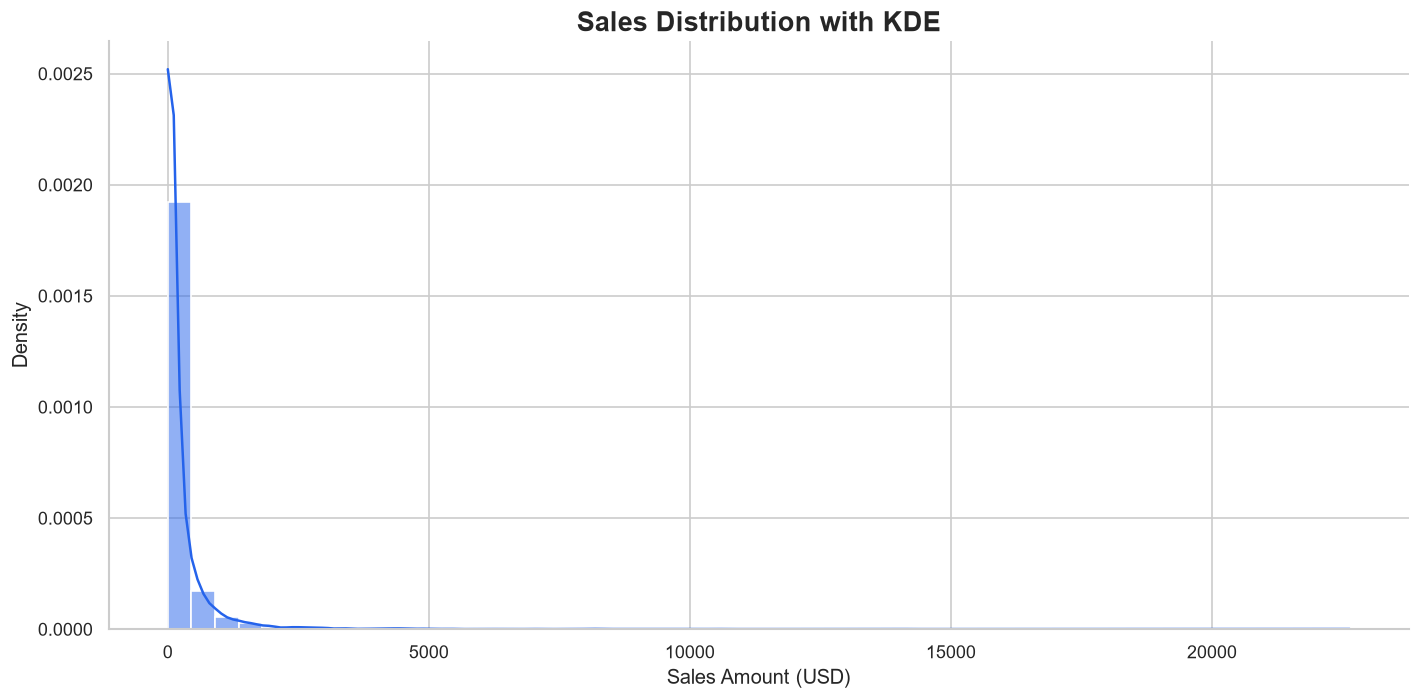

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
sns.set_theme(style="whitegrid")

# Create the figure
fig, ax = plt.subplots(figsize=(12, 6))

# Histogram with KDE
sns.histplot(
    data=df,
    x="Sales",
    bins=50,
    kde=True,
    stat="density",
    color="#2563EB",
    edgecolor="white",
    ax=ax
)

# Chart formatting
ax.set_title(
    "Sales Distribution with KDE",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Sales Amount (USD)")
ax.set_ylabel("Density")

sns.despine()
plt.tight_layout()
output_dir = root / "assets" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "distribution_kde.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "distribution_kde.svg",
    bbox_inches="tight"
)

plt.show()

In [17]:
print("SALES DISTRIBUTION ANALYSIS")
print("---------------------------")

print(f"Mean: ${df['Sales'].mean():,.2f}")
print(f"Median: ${df['Sales'].median():,.2f}")
print(f"Standard deviation: ${df['Sales'].std():,.2f}")
print(f"Skewness: {df['Sales'].skew():.2f}")
print(f"Maximum sale: ${df['Sales'].max():,.2f}")

SALES DISTRIBUTION ANALYSIS
---------------------------
Mean: $229.86
Median: $54.49
Standard deviation: $623.25
Skewness: 12.97
Maximum sale: $22,638.48


## 2.2 Profit Distribution by Category — Boxplot

This visualization compares the distribution of profits
across the three main product categories.

A boxplot displays the median, interquartile range (IQR),
whiskers, and potential outliers.

**Business Objective:**
Identify categories with high profit variability,
significant losses, and unusual transactions.

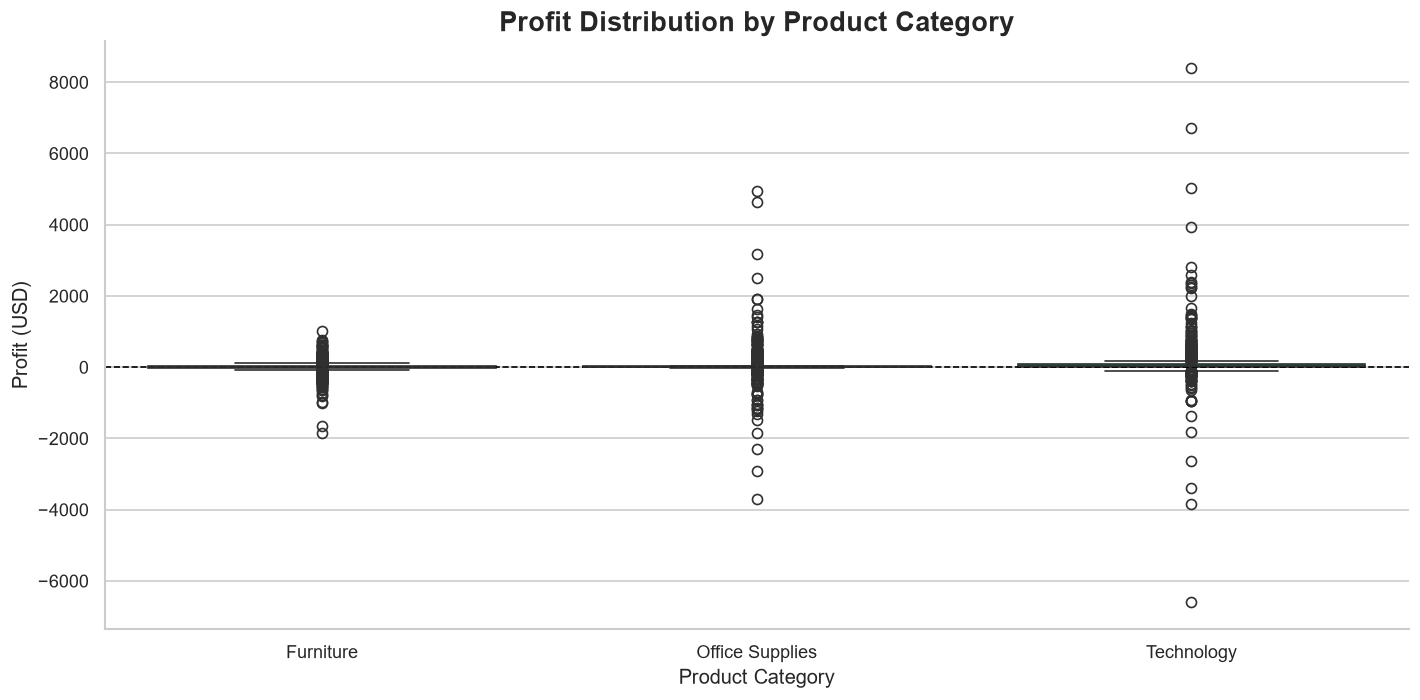

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Category",
    y="Profit",
    hue="Category",
    palette="colorblind",
    legend=False,
    ax=ax
)

ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Profit Distribution by Product Category",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Product Category")
ax.set_ylabel("Profit (USD)")

sns.despine()

plt.tight_layout()
# Export visualization
output_dir = root / "assets" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "boxplot_profit.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "boxplot_profit.svg",
    bbox_inches="tight"
)
plt.show()

In [19]:
profit_stats = df.groupby("Category")["Profit"].agg(
    Transactions="count",
    Total_Profit="sum",
    Average_Profit="mean",
    Median_Profit="median",
    Standard_Deviation="std",
    Minimum_Profit="min",
    Maximum_Profit="max"
)

losses = (
    df.assign(Is_Loss=df["Profit"] < 0)
      .groupby("Category")["Is_Loss"]
      .sum()
)

profit_stats["Loss_Transactions"] = losses

print("PROFIT ANALYSIS BY CATEGORY")
display(profit_stats.round(2))

PROFIT ANALYSIS BY CATEGORY


,Transactions,Total_Profit,Average_Profit,Median_Profit,Standard_Deviation,Minimum_Profit,Maximum_Profit,Loss_Transactions
Category,,,,,,,,
Furniture,2121,18451.27,8.70,7.77,136.05,-1862.31,1013.13,714
Office Supplies,6026,122490.80,20.33,6.88,164.89,-3701.89,4946.37,886
Technology,1847,145454.95,78.75,25.02,428.82,-6599.98,8399.98,271


### Boxplot Interpretation

The boxplot reveals significant differences in profitability
across the three product categories.

**Key Findings:**

1. **Technology** generates the highest total profit
   ($145,454.95), but also exhibits the highest variability
   and the largest individual loss (-$6,599.98).

2. **Office Supplies** generates $122,490.80 in total profit,
   with 886 loss-making transactions.

3. **Furniture** generates the lowest total profit
   ($18,451.27) and has the highest proportion of
   loss-making transactions (33.7%).

**Business Recommendation:**

Prioritize a review of pricing, discounts, and product-level
profitability within the Furniture category, while monitoring
high-risk transactions in Technology.

# 3. Uncertainty and Variability

This section evaluates the statistical uncertainty and variability
of profitability over time using confidence intervals.

The objective is to understand how average profit changes
across months and how precisely these averages are estimated.

## 3.1 Monthly Average Profit with 95% Confidence Interval

This visualization analyzes monthly average profit per
transaction and its statistical uncertainty.

The shaded band represents a 95% confidence interval
for the estimated monthly mean profit.

**Business Objective:**

Identify periods with higher or lower average profitability
and evaluate the precision of these estimates.

In [20]:
import pandas as pd
import numpy as np

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

df["Order Month"] = df["Order Date"].dt.to_period("M")

monthly_profit = (
    df.dropna(subset=["Order Month", "Profit"])
      .groupby("Order Month")["Profit"]
      .agg(["mean", "std", "count"])
      .reset_index()
)

monthly_profit["Order Month"] = (
    monthly_profit["Order Month"].dt.to_timestamp()
)

print("MONTHLY PROFIT STATISTICS")
display(monthly_profit.head())

MONTHLY PROFIT STATISTICS


,Order Month,mean,std,count
0,2014-01-01,31.015072,111.557507,79
1,2014-02-01,18.745835,38.121487,46
2,2014-03-01,3.176624,189.212042,157
3,2014-04-01,25.843224,70.898069,135
4,2014-05-01,22.448439,136.257314,122


In [21]:
from scipy.stats import t
import numpy as np

# Calculate the standard error
monthly_profit["sem"] = (
    monthly_profit["std"] /
    np.sqrt(monthly_profit["count"])
)

# Calculate the critical t-value for a 95% CI
monthly_profit["t_critical"] = t.ppf(
    0.975,
    df=monthly_profit["count"] - 1
)

# Calculate the margin of error
monthly_profit["ci_margin"] = (
    monthly_profit["t_critical"] *
    monthly_profit["sem"]
)

# Calculate confidence interval limits
monthly_profit["ci_lower"] = (
    monthly_profit["mean"] -
    monthly_profit["ci_margin"]
)

monthly_profit["ci_upper"] = (
    monthly_profit["mean"] +
    monthly_profit["ci_margin"]
)

# Display results
print("95% CONFIDENCE INTERVAL ANALYSIS")

display(
    monthly_profit[
        ["Order Month", "mean", "count", "ci_lower", "ci_upper"]
    ].head(10)
)

95% CONFIDENCE INTERVAL ANALYSIS


,Order Month,mean,count,ci_lower,ci_upper
0,2014-01-01,31.015072,79,6.027552,56.002592
1,2014-02-01,18.745835,46,7.425151,30.066519
2,2014-03-01,3.176624,157,-26.651729,33.004976
3,2014-04-01,25.843224,135,13.774661,37.911786
4,2014-05-01,22.448439,122,-1.974238,46.871117
5,2014-06-01,36.863144,135,14.195302,59.530985
6,2014-07-01,-5.884494,143,-58.177860,46.408872
7,2014-08-01,34.758856,153,18.916661,50.601051
8,2014-09-01,31.074998,268,-9.454264,71.604259
9,2014-10-01,21.687153,159,5.363978,38.010328


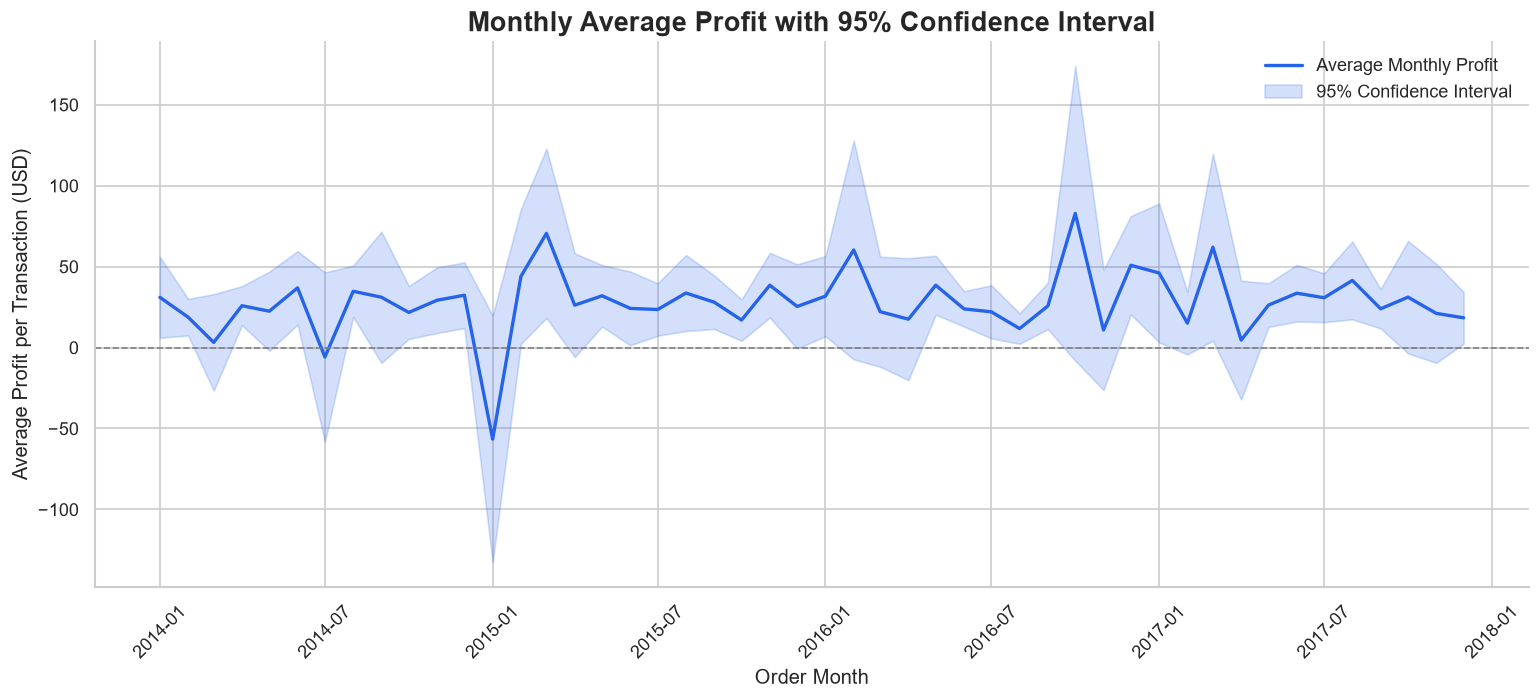

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    monthly_profit["Order Month"],
    monthly_profit["mean"],
    color="#2563EB",
    linewidth=2,
    label="Average Monthly Profit"
)

ax.fill_between(
    monthly_profit["Order Month"],
    monthly_profit["ci_lower"],
    monthly_profit["ci_upper"],
    color="#2563EB",
    alpha=0.20,
    label="95% Confidence Interval"
)

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Monthly Average Profit with 95% Confidence Interval",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Order Month")
ax.set_ylabel("Average Profit per Transaction (USD)")

ax.legend(frameon=False)
sns.despine()

plt.xticks(rotation=45)
plt.tight_layout()

output_dir = root / "assets" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "uncertainty_ci.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "uncertainty_ci.svg",
    bbox_inches="tight"
)
plt.show()

### Confidence Interval Interpretation

The monthly profitability analysis reveals fluctuations
in average profit per transaction between 2014 and 2017.

**Key Findings:**

1. **Profitability:** Most months show positive average profits.

2. **Variability:** Some months exhibit considerable fluctuations
   in profitability, including a significant decline around
   January 2015.

3. **Uncertainty:** Wider confidence intervals indicate
   less precise estimates of monthly average profit.

4. **Risk:** Several confidence intervals overlap zero,
   suggesting uncertainty about whether average profitability
   was positive during those months.

**Business Recommendation:**

Investigate months with unusually low average profits
and evaluate whether discounts, product categories,
or operational factors contributed to these results.

# 4. X-Y Relationships — Correlation Analysis

This section investigates statistical relationships between
numerical variables in the Superstore dataset.

The objective is to identify positive and negative correlations
between sales, profit, discounts, and quantity.

## 4.1 Correlation Matrix Heatmap

A correlation matrix measures the strength and direction
of linear relationships between numerical variables.

**Business Objective:**

Determine whether discounts, sales volume, and quantities
are associated with changes in profitability.

In [23]:
import pandas as pd

numeric_columns = [
    "Sales",
    "Profit",
    "Discount",
    "Quantity"
]

correlation_matrix = df[numeric_columns].corr(
    method="pearson"
)

print("CORRELATION MATRIX")
display(correlation_matrix.round(3))

CORRELATION MATRIX


,Sales,Profit,Discount,Quantity
Sales,1.000,0.479,-0.028,0.201
Profit,0.479,1.000,-0.219,0.066
Discount,-0.028,-0.219,1.000,0.009
Quantity,0.201,0.066,0.009,1.000


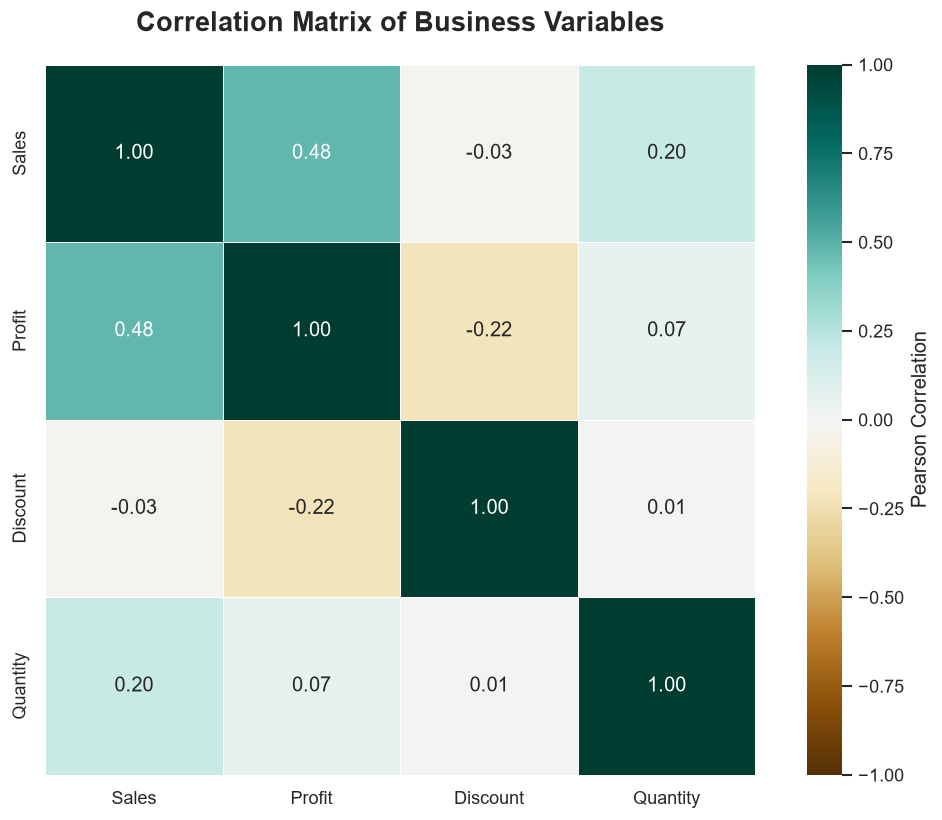

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="BrBG",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation"},
    ax=ax
)

ax.set_title(
    "Correlation Matrix of Business Variables",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

output_dir = root / "assets" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "correlation_heatmap.svg",
    bbox_inches="tight"
)

plt.show()

# 5. Interactive Web Visualization

This section presents an interactive visualization using Plotly.

The objective is to explore relationships between sales,
profitability, discounts, and product categories.

## 5.1 Interactive Sales vs. Profit Scatter Plot

Each point represents a transaction line from the
Superstore dataset.

**Business Objective:**

Identify profitable and unprofitable transactions,
explore the relationship between sales and profit,
and investigate the role of discounts across categories.

In [25]:
import plotly.express as px

scatter_data = df[
    [
        "Sales",
        "Profit",
        "Discount",
        "Category",
        "Sub-Category",
        "Product Name",
        "Region"
    ]
].copy()

scatter_data = scatter_data.dropna()

print("INTERACTIVE SCATTER DATA")
print("Total records:", len(scatter_data))

display(scatter_data.head())

INTERACTIVE SCATTER DATA
Total records: 9994


,Sales,Profit,Discount,Category,Sub-Category,Product Name,Region
0,261.9600,41.9136,0.00,Furniture,Bookcases,Bush Somerset Collection Bookcase,South
1,731.9400,219.5820,0.00,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",South
2,14.6200,6.8714,0.00,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,West
3,957.5775,-383.0310,0.45,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,South
4,22.3680,2.5164,0.20,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,South


In [26]:
fig_interactive = px.scatter(
    scatter_data,
    x="Sales",
    y="Profit",
    color="Category",
    size="Discount",
    size_max=18,
    hover_data=[
        "Sub-Category",
        "Product Name",
        "Region",
        "Discount"
    ],
    title="Interactive Sales vs. Profit Analysis",
    labels={
        "Sales": "Sales Amount (USD)",
        "Profit": "Profit (USD)",
        "Category": "Product Category"
    },
    color_discrete_map={
        "Furniture": "#2563EB",
        "Office Supplies": "#F59E0B",
        "Technology": "#8B5CF6"
    },
    opacity=0.65
)

fig_interactive.add_hline(
    y=0,
    line_dash="dash",
    line_color="gray"
)

fig_interactive.update_layout(
    template="plotly_white",
    width=1100,
    height=650,
    title_x=0.5,
    legend_title_text="Category"
)

fig_interactive.show()

### Interactive Visualization Interpretation

The interactive scatter plot explores the relationship
between sales, profit, discounts, and product categories
across 9,994 Superstore transaction lines.

**Key Findings:**

1. **Sales vs. Profit:** Higher sales do not always result
   in higher profits, as some high-value transactions
   generate significant losses.

2. **Technology:** This category contains some of the
   largest positive and negative profit outliers.

3. **Discount Risk:** Several large bubbles appear below
   the zero-profit line, suggesting that high-discount
   transactions deserve further investigation.

4. **Category Differences:** Profitability patterns vary
   across Furniture, Office Supplies, and Technology.

**Business Recommendation:**

Investigate high-discount transactions with negative
profits and review pricing policies at the product
and sub-category levels.

**Statistical Note:**

The visualization identifies associations and unusual
transactions but does not establish causation.

In [27]:
# Export interactive visualization
output_dir = root / "assets" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig_interactive.write_html(
    str(output_dir / "interactive_scatter.html"),
    include_plotlyjs=True,
    full_html=True
)

print("Interactive HTML exported successfully!")

Interactive HTML exported successfully!
